# Music DNA: the research pipeline, one step at a time

This notebook walks through the **real** research pipeline (`musicdna.experiments.pipeline.ResearchPipeline`)
on **one song**, in the same order and with the same classes:

| Step | Pipeline class | Feature stage (`feature_store.STAGES`) | What it gives |
| :--- | :--- | :--- | :--- |
| 0 | `Config` | – | every parameter |
| 1 | `CokeStudioManifest` | `StemStage` (vocal stem, read from cache here) | the song list |
| 2 | `WindowGrid` | – | the analysis windows (with pre/post-roll) |
| 3 | `AcousticFeatureExtractor` | `DspStage` | DSP descriptors per window |
| 4 | `SpatialAnalyzer` | `SpatialStage` | stereo width per window |
| 5 | `VocalPitchAnalyzer` + `SingingGate` | `VocalStage` | the singer's pitch contour |
| 6 | `IntonationAnalyzer` | `IntonationStage` | tonic (Sa) and microtonal note placement (R02) |
| 7 | `DeepAudioEncoder` | `ClapStage`, `MertStage` | CLAP / MERT embeddings |
| 8 | `ListeningEvidenceCollector` + `ImplicitPairBuilder` | – | preference pairs from listening |
| 9 | `R01Experiment` / `R02Experiment` | – | the research reports |

`LyricsStage` (Whisper transcript) is optional in the pipeline (`--lyrics`) and is not run here.
All of these run in order in `ResearchPipeline` (`musicdna.experiments.pipeline`).

**What this notebook does not do.** It does not build the corpus feature cache and writes nothing to
`data/coke_studio/features`. It analyses one song in memory. The cached vocal stem is only read.

## 0. Setup

Finds the repository root (works from `notebooks/`, the repo root, or Colab), then loads the config.

In [1]:
%matplotlib inline
import json
import os
import sys
import tempfile
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from IPython.display import HTML, Audio, display

# Never download model weights from this notebook (CLAP is used only if already cached).
os.environ.setdefault('HF_HUB_OFFLINE', '1')
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')


def resolve_workspace_root() -> Path:
    # Walk up from the current directory (and Colab's /content) to the folder holding `musicdna/`.
    candidates = []
    current = Path.cwd().resolve()
    for _ in range(6):
        candidates.append(current)
        if current.parent == current:
            break
        current = current.parent
    content_dir = Path('/content')
    if content_dir.is_dir():
        candidates += [sub for sub in content_dir.iterdir() if sub.is_dir()] + [content_dir]
    for candidate in candidates:
        if (candidate / 'musicdna').is_dir():
            return candidate.resolve()
    return Path.cwd().resolve()


workspace_root = resolve_workspace_root()
if not (workspace_root / 'musicdna').is_dir():
    raise ModuleNotFoundError('Could not locate the musicdna package. In Colab: !git clone <repo> && %cd <repo>')
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))
os.chdir(workspace_root)

from musicdna.audio.io import load_audio
from musicdna.audio.windows import WindowGrid
from musicdna.config import Config
from musicdna.corpus.coke_studio import CokeStudioManifest
from musicdna.corpus.feature_store import FEATURE_DIRECTORY, TONIC_ANNOTATIONS, FeatureStore
from musicdna.corpus.manifest import CorpusManifest
from musicdna.experiments.r01 import R01Experiment
from musicdna.experiments.r02 import R02Experiment
from musicdna.features.dsp import AcousticFeatureExtractor
from musicdna.features.embeddings import DeepAudioEncoder
from musicdna.features.intonation import JUST_INTERVALS_CENTS, IntonationAnalyzer, IntonationDescriptors
from musicdna.features.spatial import SpatialAnalyzer, SpatialDescriptors
from musicdna.features.vocal import VocalDescriptors, VocalPitchAnalyzer
from musicdna.paths import RESEARCH_OUTPUT_DIR
from musicdna.preference.implicit_pairs import ImplicitPairBuilder
from musicdna.preference.signals import ListeningEvidenceCollector

# Plot style: dark surface, one fixed colour per role.
plt.style.use('dark_background')
SURFACE, INK, MUTED = '#1a1a19', '#ffffff', '#c3c2b7'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET, RED = '#3987e5', '#d95926', '#199e70', '#c98500', '#d55181', '#9085e9', '#e66767'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': '#555', 'grid.color': '#333', 'axes.grid': True, 'grid.linewidth': 0.5,
                     'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'lines.linewidth': 1.6, 'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})


def show_table(rows: list[dict], digits: int = 3) -> None:
    # Small HTML table (pandas is not a project dependency).
    if not rows:
        print('(no rows)')
        return
    def cell(value):
        if isinstance(value, float):
            return f'{value:.{digits}f}'
        return str(value)
    head = ''.join(f'<th>{key}</th>' for key in rows[0])
    body = ''.join('<tr>' + ''.join(f'<td>{cell(v)}</td>' for v in row.values()) + '</tr>' for row in rows)
    display(HTML(f'<table style="font-size:12px"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'))


notebook_started = time.time()
print('Workspace root:', workspace_root)
print('Python:', sys.executable)

Workspace root: /Users/wahajaslam/Downloads/music-dna-player-m3-original-ui
Python: /Users/wahajaslam/Downloads/music-dna-player-m3-original-ui/.venv/bin/python


### Config: one place for every parameter

`Config.load()` reads the defaults, then `configs/default.toml` (or `MUSIC_DNA_CONFIG`), then any overrides.
The pipeline uses exactly the same call (`--set section.field=value` on the command line).

**Example:** `Config.load(overrides=['windows.window_sec=10'])` gives 10 s windows everywhere:
DSP, pitch, listening signals and the experiments all share one grid.

In [2]:
# Pipeline fingerprint: stages, experiment systems and config defaults as of this run.
# tests/python/test_notebook.py fails if this saved value differs from the code, so the notebook
# must be re-run whenever the pipeline changes.
from musicdna.experiments.pipeline import fingerprint_hash, pipeline_fingerprint
print('pipeline fingerprint:', fingerprint_hash())
print('stages:', ', '.join(pipeline_fingerprint()['stages']))
print()

config = Config.load()

# How to override (not used below; shown so you can try it):
ten_second = Config.load(overrides=['windows.window_sec=10', 'windows.hop_sec=5'])
print('override example -> window', ten_second.windows.window_sec, 's, hop', ten_second.windows.hop_sec, 's')
print('cache hash of the window section changes too:', config.section_hash('windows'), '->', ten_second.section_hash('windows'))
print()

for section, values in config.to_dict().items():
    print(f'[{section}]')
    for key, value in values.items():
        print(f'  {key:<38} {value}')

pipeline fingerprint: eb99017e4c54
stages: stems, dsp, spatial, vocal, intonation, eastern, cqt, clap, mert, lyrics

override example -> window 10.0 s, hop 5.0 s
cache hash of the window section changes too: 43718b83 -> 5090782e

[windows]
  window_sec                             12.0
  hop_sec                                6.0
  min_window_sec                         0.5
  preroll_sec                            1.0
  postroll_sec                           1.0
  embedding_context_sec                  0.0
[audio]
  analysis_sr                            22050
  stereo_sr                              44100
  max_duration_sec                       600.0
  stem_model                             htdemucs
[vocal]
  sample_rate                            16000
  hop                                    256
  fmin_hz                                70.0
  fmax_hz                                1100.0
  vibrato_min_hz                         4.0
  vibrato_max_hz                         8.5
  min_

## 1. Corpus

`CokeStudioManifest` is the versioned song list (most-viewed performances per season).
Eras: **classic** = Seasons 1-6 (Rohail Hyatt), **middle** = 7-10, **modern** = 11 onward.
`verify()` checks each audio file exists and matches its checksum; the pipeline stops if it fails.

In [3]:
manifest = CokeStudioManifest.load()
entries = manifest.entries

seasons = sorted({e.season for e in entries})
rows = []
for era in ('classic', 'middle', 'modern'):
    row = {'era': era}
    for season in seasons:
        row[f'S{season}'] = sum(e.era == era and e.season == season for e in entries) or ''
    row['total'] = sum(e.era == era for e in entries)
    rows.append(row)
print(f'{len(entries)} songs, manifest v{manifest.manifest_version}, created {manifest.created_at}')
show_table(rows)

problems = manifest.verify()
print('verify():', 'all files present and checksums match' if not problems else f'{len(problems)} problems')
for problem in problems[:10]:
    print('  ', problem)

60 songs, manifest v1, created 2026-11-04T12:14:45+00:00


era,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S12,S13,S14,S15,total
classic,4,4,4,4,4,4,,,,,,,,,,24
middle,,,,,,,4,4,4,4,,,,,,16
modern,,,,,,,,,,,4,4,4,4,4,20


verify(): all files present and checksums match


### Pick one song

We need a song whose vocal stem (Demucs `htdemucs`, 16 kHz) is already cached, because the notebook
does not run stem separation. The stem path comes from `FeatureStore.path(video_id, 'vocals')`, the same
name the pipeline writes. A **temporary** store root is used, so nothing is written to the real cache;
the stem itself is only read.

Preferred song: *Garaj Baras* (Season 1), the song the singing gate was calibrated on.
If no stem is cached anywhere, the notebook falls back to `public/demo.wav` without a stem.

In [4]:
scratch_root = Path(tempfile.mkdtemp(prefix='musicdna-notebook-'))
store = FeatureStore(config, root=scratch_root)  # temporary root: any cache writes land here, not in data/


# Stems are read from the real feature folder, or from MUSIC_DNA_STEM_DIR if set (e.g. a small test build).
# Example: MUSIC_DNA_STEM_DIR=/tmp/features after building stems for 3 songs into a temporary FeatureStore.
STEM_DIRS = [Path(os.environ['MUSIC_DNA_STEM_DIR'])] if os.environ.get('MUSIC_DNA_STEM_DIR') else []
STEM_DIRS.append(FEATURE_DIRECTORY)


def cached_stem(video_id: str) -> Path:
    # Same file name the pipeline's StemStage writes; the first folder that has it wins.
    name = store.path(video_id, 'vocals').relative_to(scratch_root)
    return next((d / name for d in STEM_DIRS if (d / name).is_file()), FEATURE_DIRECTORY / name)


def shown_path(path: Path) -> str:
    return str(path.relative_to(workspace_root)) if path.is_relative_to(workspace_root) else str(path)


PREFERRED_SONG = '7rLxN41avhY'  # Garaj Baras
with_stem = [e for e in entries if e.audio_file and cached_stem(e.video_id).is_file()
             and CorpusManifest.audio_path(e).is_file()]
song = next((e for e in with_stem if e.video_id == PREFERRED_SONG), with_stem[0] if with_stem else None)

if song is not None:
    audio_path = CorpusManifest.audio_path(song)
    stem_path = cached_stem(song.video_id)
    title = f'{song.song} | {song.artists} (S{song.season}, {song.era})'
else:
    audio_path, stem_path, title = workspace_root / 'public' / 'demo.wav', None, 'public/demo.wav (no vocal stem)'

print(f'{len(with_stem)} of {len(entries)} songs have a cached vocal stem')
print('Song :', title)
print('Audio:', audio_path.relative_to(workspace_root))
print('Stem :', shown_path(stem_path) if stem_path else 'none')

1 of 60 songs have a cached vocal stem
Song : Garaj Baras | Rahat Fateh Ali Khan & Ali Azmat (S1, classic)
Audio: data/coke_studio/audio/7rLxN41avhY.m4a
Stem : data/coke_studio/features/7rLxN41avhY/vocals_htdemucs_16000.flac


## 2. Window grid

`WindowGrid` cuts every song the same way: a window of `window_sec` starts every `hop_sec`.
With the defaults (12 s / 6 s) windows overlap by half: 0-12, 6-18, 12-24 ...

**Pre/post-roll.** Frame features need a little audio before and after the window, or the first frame
"hears" a sudden start. `context_span` widens each window by `preroll_sec` / `postroll_sec` of *real* audio
(never padding). **Example:** window 12-24 s -> analyse 11-25 s, but report only 12-24 s.
The first window 0-12 s -> 0-13 s, because there is nothing before 0 s.

In [5]:
rate = config.audio.analysis_sr
mix = load_audio(audio_path, rate)
duration = len(mix) / rate
grid = WindowGrid(config.windows)
windows = grid.windows(duration)

print(f'duration {duration:.1f} s -> {len(windows)} windows of {config.windows.window_sec:g} s, hop {config.windows.hop_sec:g} s')
for start, end in windows[:3] + windows[-2:]:
    context = grid.context_span(start, end, duration)
    print(f'  window {start:6.1f}-{end:6.1f} s  analysed as {context[0]:6.1f}-{context[1]:6.1f} s')
# 60-70 s, or the first 10 s of a shorter recording (the 32 s demo fallback).
listen_from = 60.0 if duration >= 70 else 0.0
display(Audio(mix[int(listen_from * rate):int((listen_from + 10) * rate)], rate=rate))
print(f'(audio player: {listen_from:g}-{listen_from + 10:g} s of the song)')

duration 466.0 s -> 78 windows of 12 s, hop 6 s
  window    0.0-  12.0 s  analysed as    0.0-  13.0 s
  window    6.0-  18.0 s  analysed as    5.0-  19.0 s
  window   12.0-  24.0 s  analysed as   11.0-  25.0 s
  window  456.0- 466.0 s  analysed as  455.0- 466.0 s
  window  462.0- 466.0 s  analysed as  461.0- 466.0 s


(audio player: 60-70 s of the song)


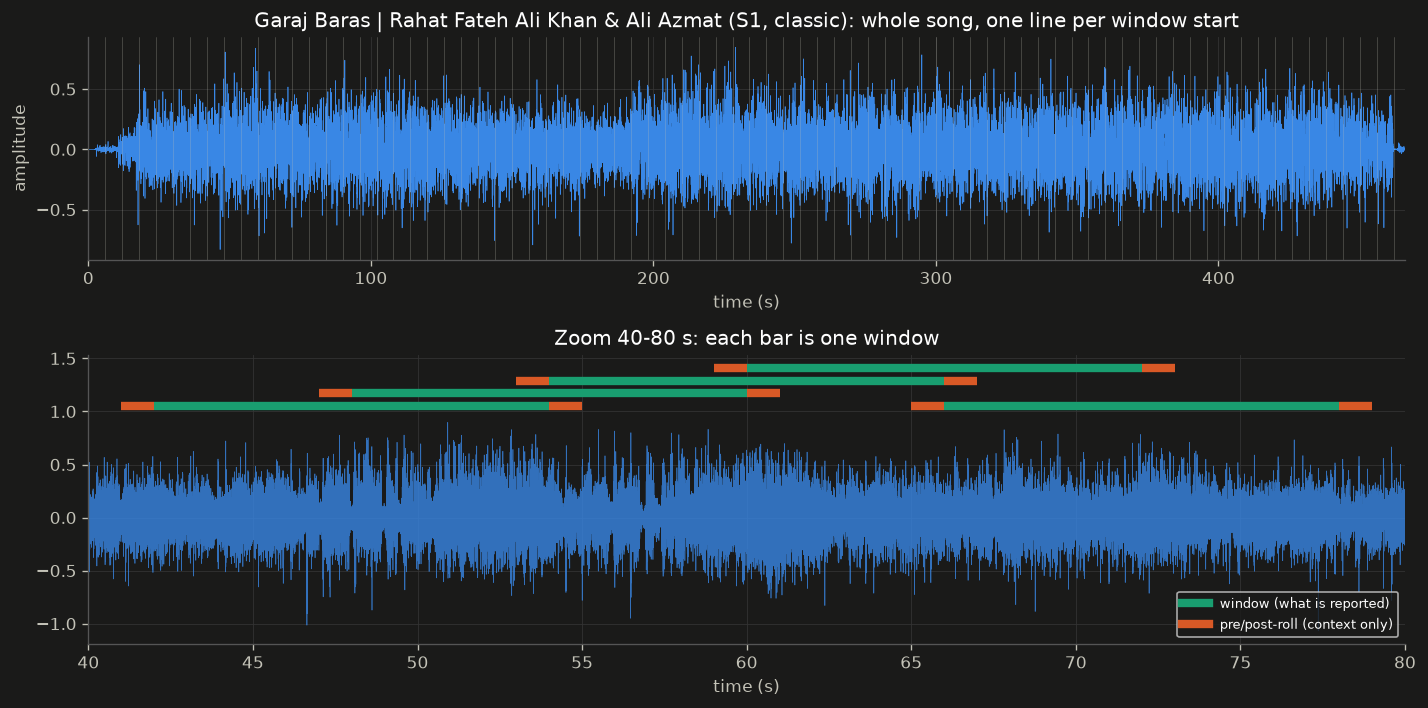

In [6]:
fig, (top, zoom) = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={'height_ratios': [1, 1.3]})
times = np.arange(len(mix)) / rate
step = max(1, len(mix) // 20000)
top.plot(times[::step], mix[::step], color=BLUE, linewidth=0.4)
for start, _ in windows:
    top.axvline(start, color=MUTED, linewidth=0.3, alpha=0.5)
top.set(title=f'{title}: whole song, one line per window start', xlabel='time (s)', ylabel='amplitude', xlim=(0, duration))

zoom_from, zoom_to = 40.0, 80.0
mask = (times >= zoom_from) & (times < zoom_to)
zoom.plot(times[mask][::20], mix[mask][::20], color=BLUE, linewidth=0.4, alpha=0.8)
shown = [w for w in windows if w[0] >= zoom_from and w[1] <= zoom_to]
for row, (start, end) in enumerate(shown):
    lo, hi = grid.context_span(start, end, duration)
    y = 1.05 + 0.12 * (row % 4)
    zoom.plot([lo, start], [y, y], color=ORANGE, linewidth=5, solid_capstyle='butt')
    zoom.plot([start, end], [y, y], color=AQUA, linewidth=5, solid_capstyle='butt')
    zoom.plot([end, hi], [y, y], color=ORANGE, linewidth=5, solid_capstyle='butt')
zoom.plot([], [], color=AQUA, linewidth=5, label='window (what is reported)')
zoom.plot([], [], color=ORANGE, linewidth=5, label='pre/post-roll (context only)')
zoom.set(title=f'Zoom {zoom_from:g}-{zoom_to:g} s: each bar is one window', xlabel='time (s)', xlim=(zoom_from, zoom_to))
zoom.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 3. DSP features (`AcousticFeatureExtractor`)

The pipeline's `DspStage` does, per window: `context_clip` (window + roll) then
`extract_window_features(clip, rate, core=...)`. Frame features are computed on the whole clip and
averaged over the **core** frames only, so the numbers still describe just the window.

Four descriptors, in plain words:
- **energy**: average loudness (RMS). Example: a quiet alaap ~0.05, full band ~0.2.
- **onset_activity**: how often new sounds start (strikes, syllables, drum hits).
- **spectral_flux**: how fast the sound's colour changes frame to frame.
- **brightness_hz**: spectral centroid; higher = more treble.

The whole song is analysed here (fast: under a second per window).

In [7]:
extractor = AcousticFeatureExtractor(config)
dsp_rows, dsp_vectors = [], []
started = time.time()
for start, end in windows:
    clip, core = extractor.context_clip(mix, rate, start, end)
    descriptors, vector = extractor.extract_window_features(clip, rate, core=core)
    dsp_vectors.append(vector)
    dsp_rows.append({'start': start, 'end': end, 'energy': descriptors['energy'],
                     'onset_activity': descriptors['onset_activity'], 'spectral_flux': descriptors['spectral_flux'],
                     'brightness_hz': descriptors['brightness_hz'], 'vocal_presence': descriptors['vocal_presence'],
                     'key': descriptors['key']})
dsp_vectors = np.array(dsp_vectors)
print(f'{len(dsp_rows)} windows in {time.time() - started:.0f} s; DSP vector per window: {dsp_vectors.shape[1]}-D')
show_table(dsp_rows[:8] + dsp_rows[-3:])

/Users/wahajaslam/Downloads/music-dna-player-m3-original-ui/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


78 windows in 67 s; DSP vector per window: 25-D


start,end,energy,onset_activity,spectral_flux,brightness_hz,vocal_presence,key
0.000,12.000,0.014,1.113,0.452,2877.600,0.685,C Minor
6.000,18.000,0.054,1.261,0.455,2623.500,0.696,E Minor
12.000,24.000,0.118,1.373,0.404,2422.700,0.547,D Major
18.000,30.000,0.150,1.532,0.396,2438.200,0.451,D Major
24.000,36.000,0.160,1.452,0.409,2353.600,0.471,D Major
30.000,42.000,0.172,1.394,0.448,2276.600,0.510,A Minor
36.000,48.000,0.173,1.367,0.455,2426.200,0.497,A Minor
42.000,54.000,0.190,1.326,0.453,2755.700,0.477,A Minor
450.000,462.000,0.148,1.641,0.385,2239.900,0.427,D Major
456.000,466.024,0.091,1.376,0.402,2380.300,0.427,A Major


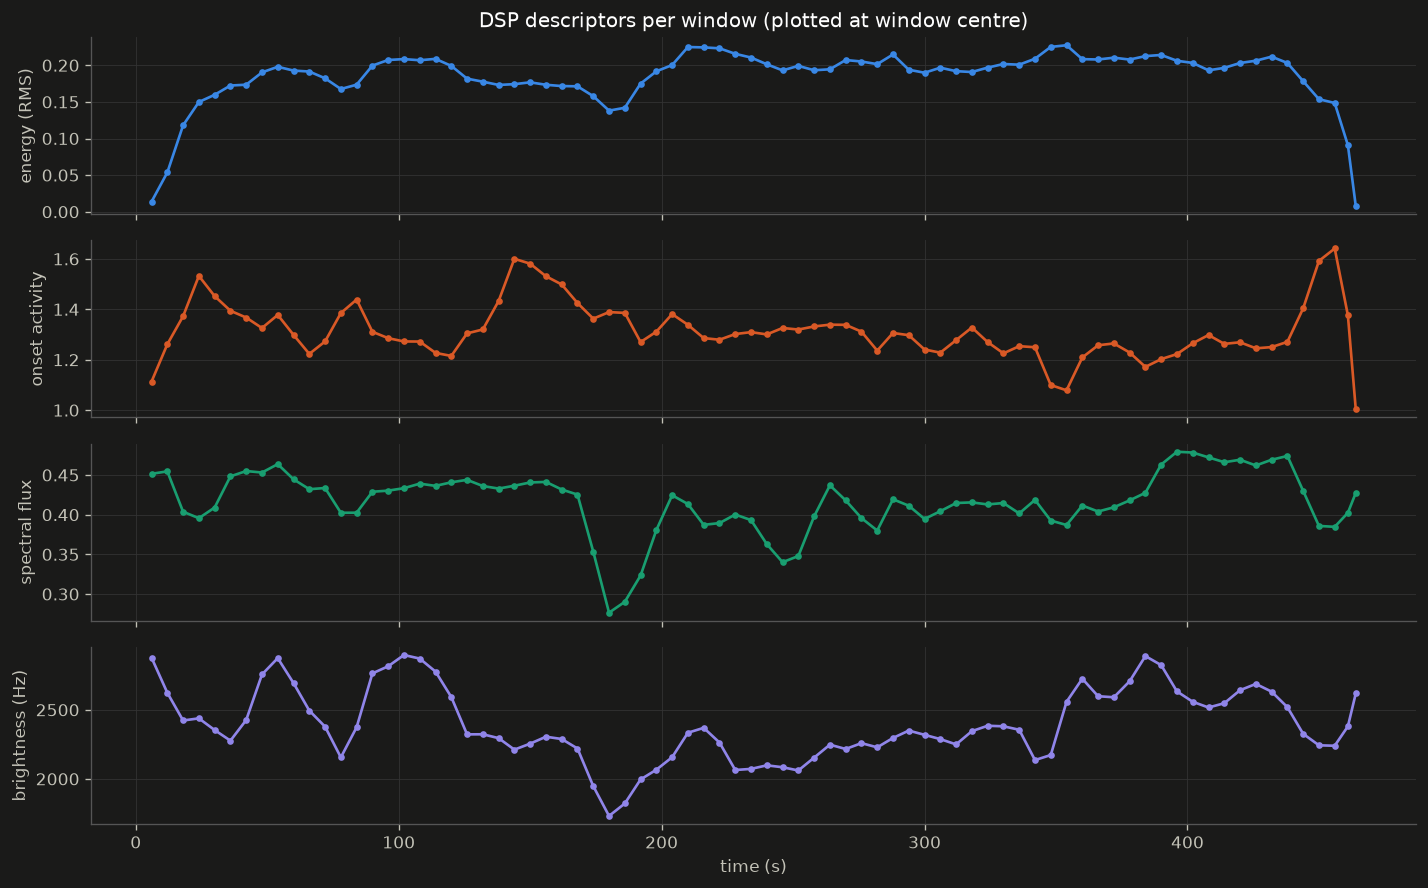

In [8]:
centres = np.array([(r['start'] + r['end']) / 2 for r in dsp_rows])
panels = [('energy', 'energy (RMS)', BLUE), ('onset_activity', 'onset activity', ORANGE),
          ('spectral_flux', 'spectral flux', AQUA), ('brightness_hz', 'brightness (Hz)', VIOLET)]
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 7.5), sharex=True)
for ax, (key, label, colour) in zip(axes, panels):
    ax.plot(centres, [r[key] for r in dsp_rows], color=colour, marker='o', markersize=3)
    ax.set_ylabel(label)
axes[0].set_title('DSP descriptors per window (plotted at window centre)')
axes[-1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

### Does the pre-roll matter? A window edge, with and without context

Onset strength compares each frame with the one before. A bare window has no "before", so its first
frames have nothing to compare with (librosa reports 0 there). With pre-roll they are measured against
the real audio before the window. Left: the onset envelope at the start of one window, bare vs with 1 s
pre-roll, in song time. Right: how much the reported `onset_activity` changes per window.
Read the numbers printed below: on this song the per-window effect is small, because only the edge
frames change. It matters more for short windows and for frames right at the edge.

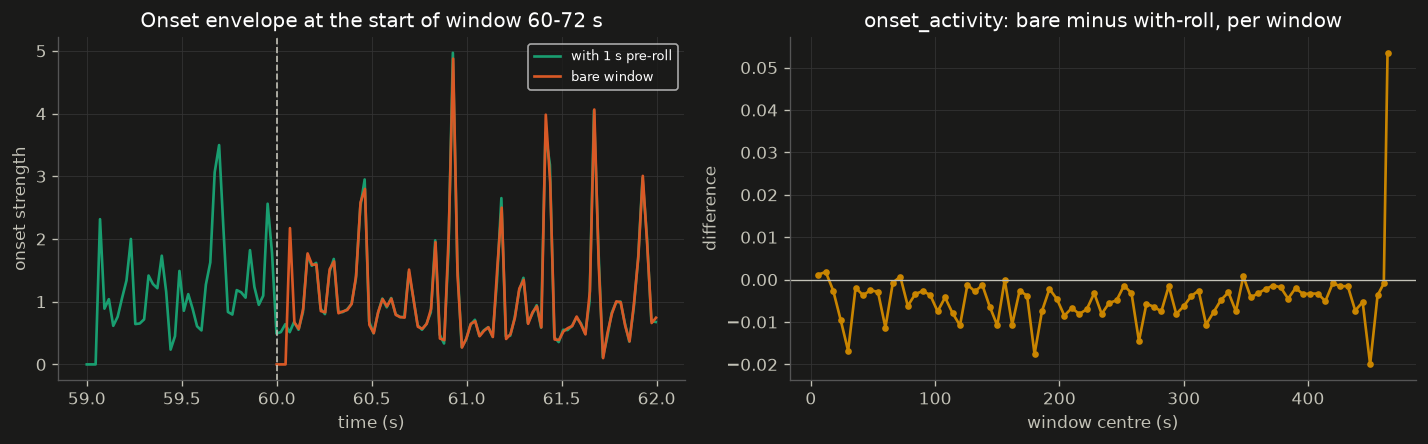

first 3 frames of the window: bare [0. 0. 0.], with roll [0.49 0.52 0.64]
median |difference| in onset_activity: 0.004 (median value 1.300)


In [9]:
import librosa

edge_start, edge_end = next(w for w in windows if w[0] >= 60)
bare = mix[int(edge_start * rate):int(edge_end * rate)]
context, core = extractor.context_clip(mix, rate, edge_start, edge_end)
hop = 512
onset_bare = librosa.onset.onset_strength(y=bare, sr=rate, hop_length=hop)
onset_context = librosa.onset.onset_strength(y=context, sr=rate, hop_length=hop)
t_bare = edge_start + librosa.frames_to_time(np.arange(onset_bare.size), sr=rate, hop_length=hop)
t_context = edge_start - core[0] + librosa.frames_to_time(np.arange(onset_context.size), sr=rate, hop_length=hop)

with_roll = np.array([r['onset_activity'] for r in dsp_rows])   # from the cell above (with roll)
without_roll = np.array([extractor.extract_window_features(mix[int(a * rate):int(b * rate)], rate)[0]['onset_activity']
                         for a, b in windows])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
show = lambda t: (t >= edge_start - 1) & (t < edge_start + 2)
left.plot(t_context[show(t_context)], onset_context[show(t_context)], color=AQUA, label='with 1 s pre-roll')
left.plot(t_bare[show(t_bare)], onset_bare[show(t_bare)], color=ORANGE, label='bare window')
left.axvline(edge_start, color=MUTED, linestyle='--', linewidth=1)
left.set(title=f'Onset envelope at the start of window {edge_start:g}-{edge_end:g} s', xlabel='time (s)', ylabel='onset strength')
left.legend(fontsize=8)
right.plot(centres, without_roll - with_roll, color=YELLOW, marker='o', markersize=3)
right.axhline(0, color=MUTED, linewidth=0.8)
right.set(title='onset_activity: bare minus with-roll, per window', xlabel='window centre (s)', ylabel='difference')
plt.tight_layout()
plt.show()
print(f'first 3 frames of the window: bare {onset_bare[:3].round(2)}, with roll {onset_context[int(core[0] * rate / hop):][:3].round(2)}')
print(f'median |difference| in onset_activity: {np.median(np.abs(without_roll - with_roll)):.3f} '
      f'(median value {np.median(with_roll):.3f})')

## 4. Spatial image (`SpatialAnalyzer`)

Stereo descriptors from mid/side energy. Plain words:
- **width**: share of side energy. 0 = mono, 0.5 = left and right unrelated. Example: a centred solo voice is narrow.
- **correlation**: left vs right. 1 = identical (mono), near 0 = very wide, negative = phasey.
- **low/mid/high width**: the same per band (edges from `spatial.band_edges_hz`).

Clips come from `FeatureStore.context_clips(..., mono=False)`, exactly as `SpatialStage` does
(on the temporary store, so its `duration.json` lands in the temp folder).

78 windows x 7 spatial descriptors


start,width,correlation,balance,low_width,mid_width,high_width,width_variation
0.000,0.271,0.464,0.164,0.374,0.261,0.408,0.155
6.000,0.153,0.698,0.106,0.014,0.185,0.221,0.132
12.000,0.088,0.825,0.073,0.004,0.164,0.261,0.101
18.000,0.065,0.870,0.061,0.002,0.162,0.278,0.062
24.000,0.080,0.839,0.006,0.015,0.164,0.256,0.052
30.000,0.094,0.813,-0.046,0.031,0.149,0.225,0.044


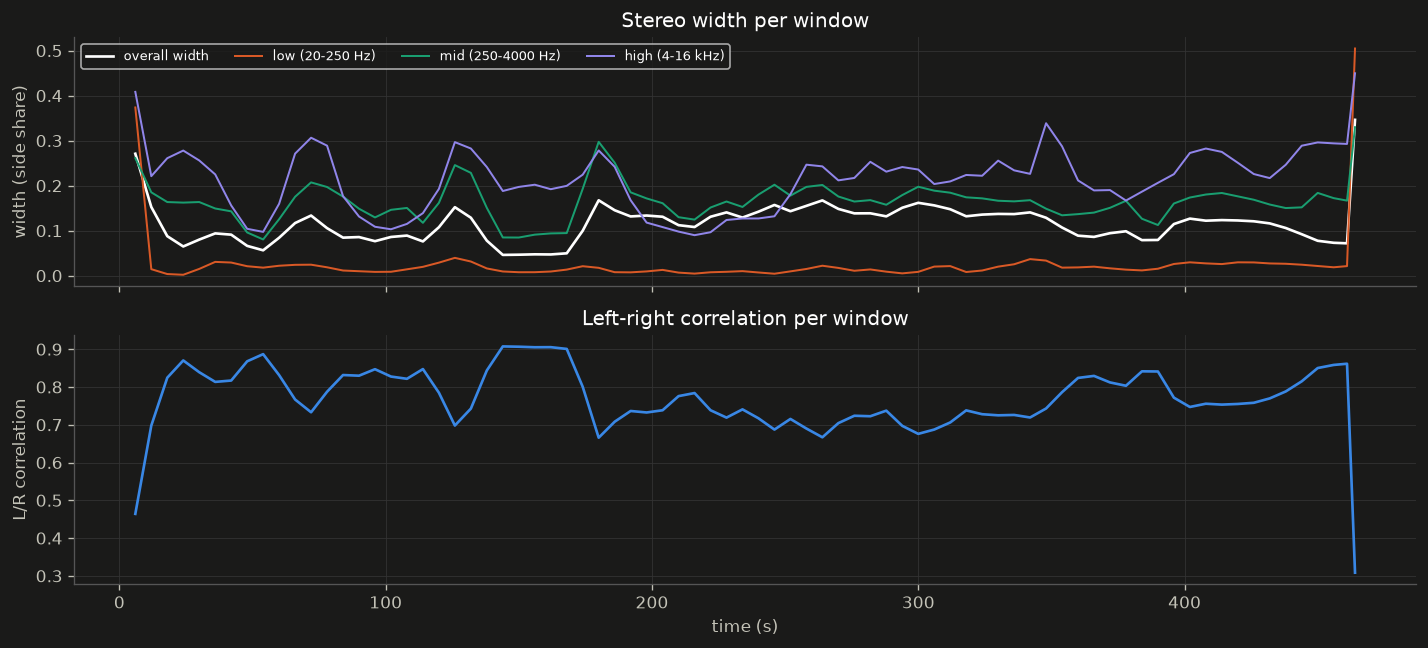

In [10]:
spatial = SpatialAnalyzer(config.spatial)
stereo_rate = config.audio.stereo_sr
if song is not None:
    stereo_clips = store.context_clips(song, stereo_rate, mono=False)
else:
    stereo = load_audio(audio_path, stereo_rate, mono=False)
    stereo_clips = []
    for start, end in windows:
        lo, hi = grid.context_span(start, end, stereo.shape[-1] / stereo_rate)
        stereo_clips.append((stereo[..., int(lo * stereo_rate):int(hi * stereo_rate)], (start - lo, end - lo)))
spatial_rows = [spatial.describe(clip, stereo_rate, core) for clip, core in stereo_clips]
spatial_matrix = np.array([d.to_vector() for d in spatial_rows])
print(f'{len(spatial_rows)} windows x {len(SpatialDescriptors.NAMES)} spatial descriptors')
show_table([{'start': w[0], **dict(zip(SpatialDescriptors.NAMES, map(float, v)))} for w, v in list(zip(windows, spatial_matrix))[:6]])

spatial_centres = np.array([(a + b) / 2 for a, b in windows[:len(spatial_rows)]])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax1.plot(spatial_centres, spatial_matrix[:, 0], color=INK, label='overall width')
for index, name, colour in ((3, 'low (20-250 Hz)', ORANGE), (4, 'mid (250-4000 Hz)', AQUA), (5, 'high (4-16 kHz)', VIOLET)):
    ax1.plot(spatial_centres, spatial_matrix[:, index], color=colour, label=name, linewidth=1.2)
ax1.set(ylabel='width (side share)', title='Stereo width per window')
ax1.legend(fontsize=8, ncol=4)
ax2.plot(spatial_centres, spatial_matrix[:, 1], color=BLUE)
ax2.set(ylabel='L/R correlation', xlabel='time (s)', title='Left-right correlation per window')
plt.tight_layout()
plt.show()

## 5. Vocal pitch (`VocalPitchAnalyzer` + `SingingGate`)

pYIN tracks the singer's pitch on the **vocal stem** on a 2-cent grid (`vocal.pitch_resolution_cents`).
It is never snapped to piano keys.

**Singing gate.** Demucs leaves faint instruments in the vocal stem (harmonium, sarangi). When the singer
rests, pYIN would track that instrument. The gate keeps a frame only if the stem is not buried under the
accompaniment (default: vocal at least -15 dB relative to the rest of the mix) and not near-silent.
**Example:** singer silent, sarangi playing: the stem is ~30 dB below the accompaniment -> frame dropped.

The pipeline's `VocalStage` passes `accompaniment = mix - vocals` at 16 kHz. We do the same.

**Excerpt.** To keep the notebook fast, pitch is analysed on **60-150 s** (90 s) of the song, not the whole
song. The pipeline tracks the whole song. We track twice (gate on, gate off) only to show which frames
the gate removed.

In [11]:
EXCERPT = (60.0, 150.0)
vocal_rate = config.vocal.sample_rate
pitch = VocalPitchAnalyzer(config.vocal)
if stem_path is not None:
    vocals_full, stem_rate = sf.read(stem_path, dtype='float32')
    assert stem_rate == vocal_rate
    mix_16k = load_audio(audio_path, vocal_rate)
    length = min(len(vocals_full), len(mix_16k))
    a, b = int(EXCERPT[0] * vocal_rate), min(int(EXCERPT[1] * vocal_rate), length)
    vocals = vocals_full[a:b]
    accompaniment = mix_16k[a:b] - vocals
else:
    # Fallback: no stem, so the gate can only use its loudness rule (no accompaniment).
    vocals = load_audio(audio_path, vocal_rate)[int(EXCERPT[0] * vocal_rate):int(EXCERPT[1] * vocal_rate)]
    accompaniment = None

started = time.time()
contour = pitch.track(vocals, vocal_rate, accompaniment)
gate = pitch.last_gate
ungated = VocalPitchAnalyzer(replace(config.vocal, gate_enabled=False)).track(vocals, vocal_rate)
print(f'pitch tracked on {len(vocals) / vocal_rate:.0f} s in {time.time() - started:.0f} s '
      f'({contour.frame_rate:.1f} frames/s)')
print('gate report:', json.dumps(gate.to_dict()))
print(f'kept {gate.kept_fraction:.1%} of the {gate.tracked_frames} frames pYIN called voiced')
display(Audio(vocals[:10 * vocal_rate], rate=vocal_rate))
print(f'(vocal stem, {EXCERPT[0]:g}-{EXCERPT[0] + 10:g} s)')

pitch tracked on 90 s in 40 s (62.5 frames/s)
gate report: {"tracked_frames": 4299, "kept_frames": 3872, "kept_fraction": 0.9007, "removed_by": {"quiet_vocal": 78, "low_voicing_probability": 0, "buried_under_accompaniment": 349}}
kept 90.1% of the 4299 frames pYIN called voiced


(vocal stem, 60-70 s)


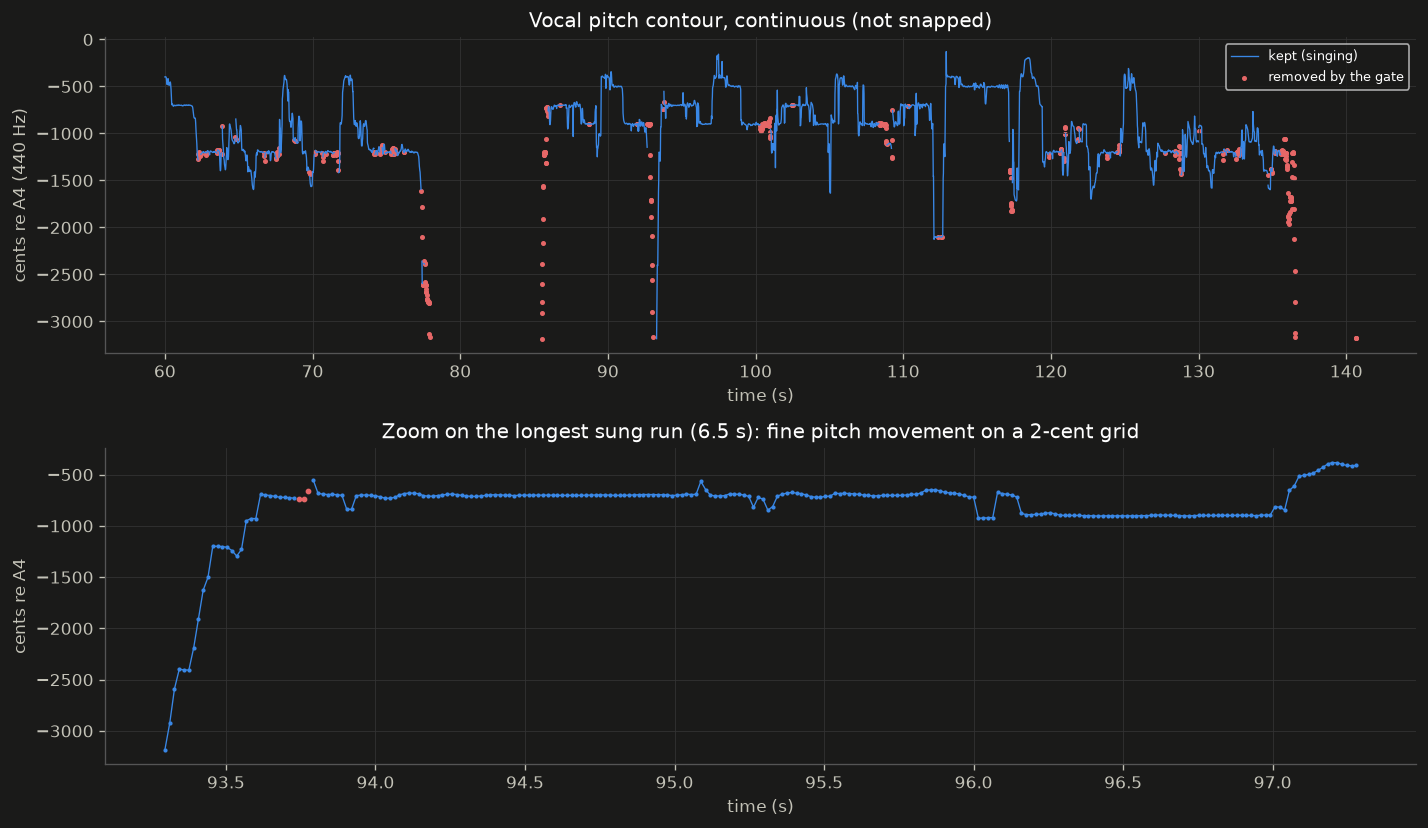

distinct pitch values in that run: 88


In [12]:
song_time = contour.times + EXCERPT[0]
cents = (contour.semitones - 69) * 100          # continuous cents relative to A4 = 440 Hz
dropped = np.isnan(contour.semitones) & ~np.isnan(ungated.semitones)
dropped_cents = (ungated.semitones - 69) * 100

fig, (full, detail) = plt.subplots(2, 1, figsize=(12, 7))
full.plot(song_time, cents, color=BLUE, linewidth=0.8, label='kept (singing)')
full.scatter(song_time[dropped], dropped_cents[dropped], s=4, color=RED, label='removed by the gate')
full.set(title='Vocal pitch contour, continuous (not snapped)', xlabel='time (s)', ylabel='cents re A4 (440 Hz)')
full.legend(fontsize=8, loc='upper right')

voiced = ~np.isnan(contour.semitones)
run_lengths = np.diff(np.flatnonzero(np.diff(np.r_[0, voiced.astype(int), 0])))[::2]
starts = np.flatnonzero(np.diff(np.r_[0, voiced.astype(int)]) == 1)
longest = starts[np.argmax(run_lengths)]
lo = max(0, longest - int(0.5 * contour.frame_rate))
hi = min(len(cents), lo + int(4 * contour.frame_rate))
detail.plot(song_time[lo:hi], cents[lo:hi], color=BLUE, marker='.', markersize=3, linewidth=0.8)
detail.scatter(song_time[lo:hi][dropped[lo:hi]], dropped_cents[lo:hi][dropped[lo:hi]], s=6, color=RED)
detail.set(title=f'Zoom on the longest sung run ({run_lengths.max() / contour.frame_rate:.1f} s): fine pitch movement on a 2-cent grid',
           xlabel='time (s)', ylabel='cents re A4')
plt.tight_layout()
plt.show()
print(f'distinct pitch values in that run: {len(np.unique(cents[lo:hi][~np.isnan(cents[lo:hi])]))}')

### Per-window vocal descriptors

`VocalPitchAnalyzer.describe(contour, start, end)` gives 9 numbers per window, in semitones.
Example: `vibrato_rate_hz` 5.5 and `vibrato_extent_st` 0.4 = a 5.5 Hz wobble about 40 cents wide.
Contour time 0 is the excerpt start, so window times are shifted by 60 s.

In [13]:
excerpt_windows = [w for w in windows if w[0] >= EXCERPT[0] and w[1] <= EXCERPT[1]]
vocal_rows = []
for start, end in excerpt_windows:
    d = pitch.describe(contour, start - EXCERPT[0], end - EXCERPT[0])
    vocal_rows.append({'window': f'{start:g}-{end:g}', **d.to_dict()})
show_table(vocal_rows)

window,voiced_fraction,median_pitch_st,pitch_range_st,glide_st_per_sec,pitch_velocity_st_per_sec,longest_sustain_sec,vibrato_rate_hz,vibrato_extent_st,ornament_rate_per_sec
60-72,0.907,57.105,9.341,-0.361,7.994,2.256,5.951,0.950,1.667
66-78,0.855,57.095,9.920,-0.117,7.972,2.416,5.535,1.131,1.500
72-84,0.416,57.255,8.555,-1.571,7.538,2.176,5.147,0.786,0.417
78-90,0.333,61.835,6.273,0.025,6.642,1.952,5.389,1.384,0.583
84-96,0.775,61.895,6.440,-0.079,6.445,3.232,5.593,1.014,1.583
90-102,0.883,61.795,6.560,-0.022,5.502,6.512,5.899,1.379,2.167
96-108,0.937,61.175,5.716,-0.065,5.718,5.472,0.000,0.000,2.667
102-114,0.940,61.855,13.864,-0.155,6.355,5.824,5.621,1.854,2.750
108-120,0.925,62.885,15.332,0.250,5.689,4.592,5.790,1.394,1.750
114-126,0.945,60.275,11.992,-0.519,7.200,3.200,5.255,0.970,1.750


## 6. Intonation: the R02 features (`IntonationAnalyzer`)

**Tonic (Sa).** Found from held notes: the most-sung pitch class, supported by its fifth (Pa, +702 cents).
It is a continuous value. Sa can sit between piano keys. **Example:** MIDI 57.35 = A3 + 35 cents.

**Held notes.** Smooth the contour to remove vibrato, then keep stretches that move slower than
150 cents/s for at least 0.15 s. A **slide in** (meend) is the voice approaching from 80+ cents away.

**Deviation.** Each held note is placed relative to Sa and compared with two grids, both built on Sa:
equal temperament (every 100 cents) and just intonation (simple ratios, e.g. 5/4 = 386 cents).
**Example:** Ga at 375 cents: 25 cents flat of the ET grid, 11 cents flat of the just third. Neither is "correct".

Here the tonic comes from the 90 s excerpt only; the pipeline uses the whole song (and a hand-annotated
tonic from `tonic_annotations.json` when one exists).

In [14]:
intonation = IntonationAnalyzer(config.intonation)
tonic = intonation.estimate_tonic(contour)
notes = intonation.held_notes(contour)

annotations = json.loads(TONIC_ANNOTATIONS.read_text()) if TONIC_ANNOTATIONS.exists() else {}
annotated_hz = annotations.get(song.video_id) if song is not None else None
print(f'tonic (detected): {tonic.hz:.1f} Hz = MIDI {tonic.midi:.2f} = {librosa.midi_to_note(tonic.midi, cents=True)}')
print(f'confidence      : {tonic.confidence:.2f}  (0 = runner-up just as strong, 1 = no competitor)')
if annotated_hz:
    error = ((tonic.midi - (69 + 12 * np.log2(annotated_hz / 440))) * 100 + 600) % 1200 - 600
    print(f'annotated tonic : {annotated_hz} Hz -> detection error {error:+.0f} cents')
else:
    print('annotated tonic : none for this song, so detection accuracy is unmeasured')
slides = [n for n in notes if n.glide_in_cents > 0]
print(f'held notes      : {len(notes)}, of which {len(slides)} reached by a slide')

tonic (detected): 220.3 Hz = MIDI 57.02 = A3+2
confidence      : 0.13  (0 = runner-up just as strong, 1 = no competitor)
annotated tonic : none for this song, so detection accuracy is unmeasured
held notes      : 52, of which 20 reached by a slide


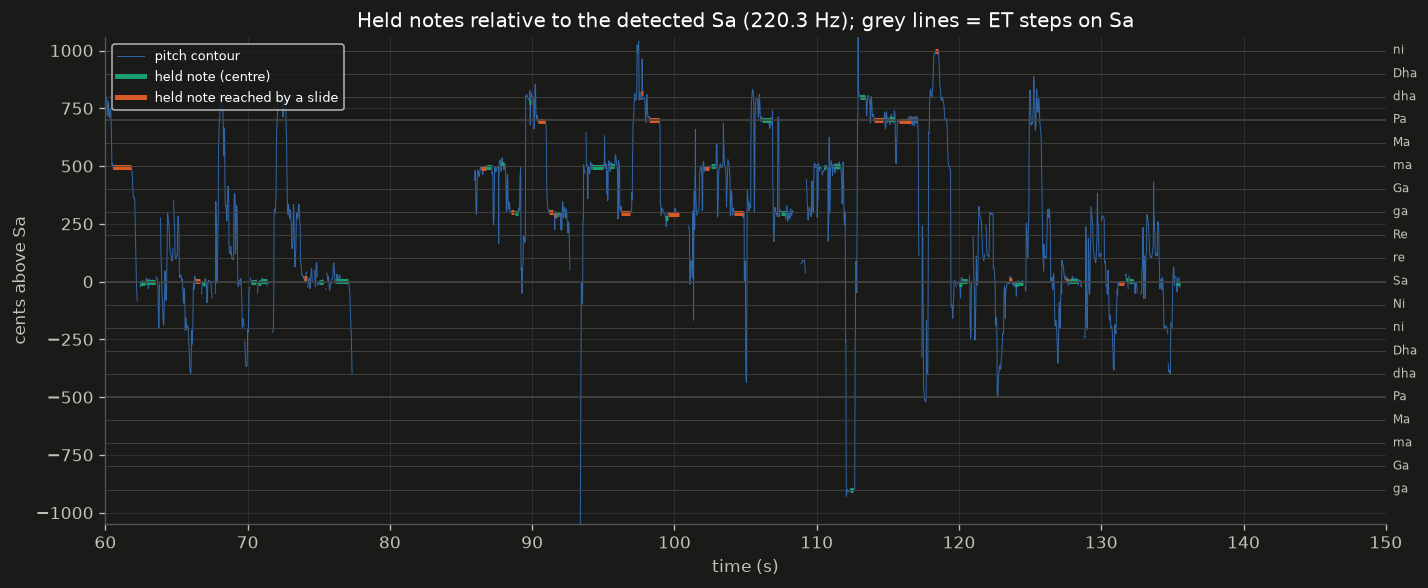

In [15]:
SARGAM = ['Sa', 're', 'Re', 'ga', 'Ga', 'ma', 'Ma', 'Pa', 'dha', 'Dha', 'ni', 'Ni']
relative_cents = (contour.semitones - tonic.midi) * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(song_time, relative_cents, color=BLUE, linewidth=0.6, alpha=0.7, label='pitch contour')
for note in notes:
    y = (note.centre_midi - tonic.midi) * 100
    ax.plot([song_time[note.start], song_time[min(note.end, len(song_time) - 1)]], [y, y],
            color=ORANGE if note.glide_in_cents > 0 else AQUA, linewidth=3, solid_capstyle='butt')
ax.plot([], [], color=AQUA, linewidth=3, label='held note (centre)')
ax.plot([], [], color=ORANGE, linewidth=3, label='held note reached by a slide')
low, high = np.nanpercentile(relative_cents, [1, 99])
for octave in range(int(np.floor(low / 1200)), int(np.ceil(high / 1200)) + 1):
    for step, name in enumerate(SARGAM):
        level = octave * 1200 + step * 100
        if low - 100 <= level <= high + 100:
            ax.axhline(level, color='#444', linewidth=0.5 if name not in ('Sa', 'Pa') else 1.0)
            ax.text(EXCERPT[1] + 0.5, level, name, fontsize=7, color=MUTED, va='center')
ax.set(title=f'Held notes relative to the detected Sa ({tonic.hz:.1f} Hz); grey lines = ET steps on Sa',
       xlabel='time (s)', ylabel='cents above Sa', xlim=(EXCERPT[0], EXCERPT[1]), ylim=(low - 150, high + 150))
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

### Each held note: where it sits against both grids

The same arithmetic `IntonationAnalyzer.describe` uses: position above Sa within one octave,
distance to the nearest ET step, distance to the nearest just ratio.

time_s,length_s,swara,cents_above_Sa,et_dev_cents,just_dev_cents,wobble_cents,slide_in_cents
60.6,1.2,ma,497.0,-3.0,1.0,1.6,278.4
62.4,0.3,Sa,1194.8,-5.2,5.2,3.1,0.0
62.8,0.7,Sa,0.3,0.3,0.3,2.0,0.0
66.3,0.4,Sa,2.3,2.3,2.3,3.2,341.4
66.8,0.2,Sa,1193.9,-6.1,6.1,5.8,0.0
70.2,0.4,Sa,0.3,0.3,0.3,0.8,0.0
70.7,0.2,Sa,1194.4,-5.6,5.6,3.0,0.0
71.0,0.4,Sa,4.0,4.0,4.0,4.3,0.0
73.9,0.2,Sa,15.6,15.6,15.6,3.2,286.5
75.0,0.3,Sa,1198.4,-1.6,1.6,2.3,0.0


52 held notes: median |ET deviation| 3.5 cents, 4% further than 20 cents from the ET grid


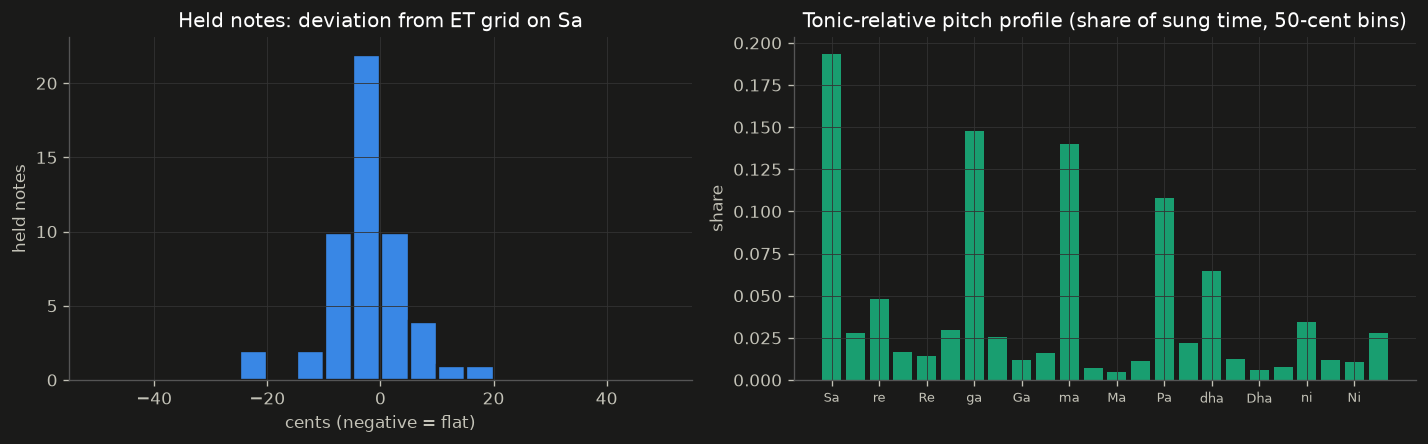

In [16]:
note_rows = []
for note in notes:
    position = float(np.mod((note.centre_midi - tonic.midi) * 100, 1200))
    et_deviation = (position + 50) % 100 - 50
    just_deviation = float(np.min(np.abs((position - JUST_INTERVALS_CENTS + 600) % 1200 - 600)))
    note_rows.append({'time_s': float(song_time[note.start]), 'length_s': (note.end - note.start) / contour.frame_rate,
                      'swara': SARGAM[int(round(position / 100)) % 12], 'cents_above_Sa': position,
                      'et_dev_cents': et_deviation, 'just_dev_cents': just_deviation,
                      'wobble_cents': note.wobble_cents, 'slide_in_cents': note.glide_in_cents})
show_table(note_rows[:15], digits=1)
et_abs = np.abs([r['et_dev_cents'] for r in note_rows])
print(f'{len(note_rows)} held notes: median |ET deviation| {np.median(et_abs):.1f} cents, '
      f'{np.mean(et_abs > config.intonation.offgrid_threshold_cents):.0%} further than '
      f'{config.intonation.offgrid_threshold_cents:g} cents from the ET grid')

fig, (hist, prof) = plt.subplots(1, 2, figsize=(12, 3.8))
hist.hist([r['et_dev_cents'] for r in note_rows], bins=np.arange(-50, 51, 5), color=BLUE, edgecolor=SURFACE, linewidth=2)
hist.set(title='Held notes: deviation from ET grid on Sa', xlabel='cents (negative = flat)', ylabel='held notes')

profile = intonation.profile(contour, tonic, 0.0, contour.times[-1] + 1)
bins = config.intonation.profile_bins
prof.bar(np.arange(bins), profile, color=AQUA, width=0.8)
prof.set_xticks(np.arange(0, bins, bins // 12), SARGAM, fontsize=8)
prof.set(title='Tonic-relative pitch profile (share of sung time, 50-cent bins)', ylabel='share')
plt.tight_layout()
plt.show()

### Per-window intonation descriptors (what R02 uses)

8 numbers per window plus the 24-bin profile. Example: `grid_alignment` near 1 means held notes keep
one fixed offset from the 100-cent grid (consistent tuning), whatever the tonic.

In [17]:
intonation_rows = []
for start, end in excerpt_windows:
    d = intonation.describe(contour, tonic, start - EXCERPT[0], end - EXCERPT[0])
    intonation_rows.append({'window': f'{start:g}-{end:g}', **d.to_dict()})
show_table(intonation_rows, digits=2)

window,held_note_fraction,et_deviation_mean_abs_cents,et_offgrid_fraction,grid_alignment,just_deviation_mean_abs_cents,held_note_wobble_cents,glide_in_fraction,glide_in_mean_cents
60-72,0.35,3.34,0.00,0.97,3.09,2.96,0.25,309.87
66-78,0.29,4.74,0.00,0.92,4.74,3.77,0.25,313.96
72-84,0.28,6.57,0.00,0.90,6.57,4.37,0.33,286.54
78-90,0.38,7.42,0.17,0.85,14.59,2.16,0.33,150.71
84-96,0.40,6.09,0.08,0.90,13.59,2.14,0.42,206.19
90-102,0.43,6.88,0.09,0.86,14.35,2.37,0.64,167.10
96-108,0.40,6.21,0.10,0.86,12.95,2.80,0.60,134.57
102-114,0.29,2.48,0.00,0.99,9.15,2.80,0.22,183.62
108-120,0.28,2.45,0.00,0.99,8.37,3.00,0.38,138.77
114-126,0.29,5.27,0.00,0.94,7.44,3.10,0.44,184.21


## 6b. Eastern ensemble features (`EasternStage`)

The rest of the ensemble, not only the voice: roughness, build-up, drone, tempo arc, percussion density,
and how much of the melodic instruments' pitch energy sits between Western semitones (`instrument_offgrid`).
The pipeline reads the Demucs **drums** and **other** stems (tabla and dholak land in drums; sitar, sarangi,
harmonium and oud in other). The notebook does not run Demucs, so if those stems are not cached it splits
the accompaniment with HPSS instead: percussive part for drums, harmonic part for other. That is enough to
show the features, not to measure them.

In [18]:
import librosa
from musicdna.features.eastern import EASTERN_FEATURES, EasternFeatureExtractor

def cached_excerpt_stem(name):
    # Same folder and naming as the vocal stem: vocals_htdemucs_16000.flac -> drums_htdemucs_16000.flac
    if stem_path is None:
        return None
    path = stem_path.with_name(stem_path.name.replace('vocals_', f'{name}_', 1))
    if not path.is_file():
        return None
    full, _ = sf.read(path, dtype='float32')
    return full[int(EXCERPT[0] * vocal_rate):int(EXCERPT[1] * vocal_rate)]

backing = accompaniment if accompaniment is not None else load_audio(audio_path, vocal_rate)[
    int(EXCERPT[0] * vocal_rate):int(EXCERPT[1] * vocal_rate)]
harmonic, percussive = librosa.effects.hpss(backing)
drums, other = cached_excerpt_stem('drums'), cached_excerpt_stem('other')
source = 'Demucs stems' if drums is not None and other is not None else 'HPSS stand-in (no Demucs drums/other cached)'
drums = percussive if drums is None else drums
other = harmonic if other is None else other

analysis_rate = config.audio.analysis_sr
mix_excerpt = load_audio(audio_path, analysis_rate)[int(EXCERPT[0] * analysis_rate):int(EXCERPT[1] * analysis_rate)]
local_windows = [(s - EXCERPT[0], e - EXCERPT[0]) for s, e in excerpt_windows]
eastern = EasternFeatureExtractor().song(mix_excerpt, analysis_rate,
                                         {'vocals': vocals, 'drums': drums, 'other': other}, vocal_rate, local_windows)
print(f'{len(local_windows)} windows x {len(EASTERN_FEATURES)} Eastern features, from {source}')
show_table([{'window': f'{s:g}-{e:g}', **dict(zip(EASTERN_FEATURES, map(float, row)))}
            for (s, e), row in zip(excerpt_windows, eastern)], digits=2)

14 windows x 12 Eastern features, from Demucs stems


window,roughness,energy_slope,energy_gain,drone_strength,tempo_bpm,tempo_change,percussion_onset_rate,percussion_share,instrument_share,instrument_offgrid,instrument_solo,voice_instrument_alternation
60-72,0.01,-0.18,0.00,0.46,123.05,0.00,4.42,0.32,0.10,0.09,0.00,55.00
66-78,0.01,-0.06,-0.05,0.42,123.05,0.00,5.08,0.36,0.12,0.08,0.02,55.00
72-84,0.01,-0.26,-0.09,0.41,123.05,0.00,5.17,0.46,0.22,0.07,0.52,15.00
78-90,0.01,0.44,0.03,0.31,123.05,0.00,5.17,0.46,0.19,0.08,0.65,5.00
84-96,0.01,0.20,0.15,0.27,123.05,0.00,5.08,0.31,0.07,0.13,0.15,25.00
90-102,0.01,-0.02,0.04,0.26,123.05,0.00,4.67,0.27,0.06,0.14,0.03,30.00
96-108,0.01,0.04,0.01,0.26,123.05,0.00,4.67,0.28,0.05,0.12,0.03,20.00
102-114,0.01,0.01,-0.01,0.28,123.05,0.00,4.75,0.30,0.05,0.09,0.00,20.00
108-120,0.01,0.09,0.01,0.29,123.05,0.00,4.50,0.32,0.05,0.09,0.00,10.00
114-126,0.01,-0.23,-0.05,0.42,123.05,0.00,4.75,0.34,0.07,0.09,0.00,10.00


## 6c. Fine-pitch pictures for the moment model's CNN (`CqtStage`)

A CQT with 60 rows per octave (20 cents per row) of the mix and each stem. Two views are cut from one array:
the **tonic view** shifts every song so Sa sits on row 0 (komal re then lands on the same rows in any key);
the **western view** pools the equal-tempered grid to one row per semitone, which averages microtones away.

stored (4, 420, 704) (channels, rows, frames); tonic offset -15 rows, from vocal


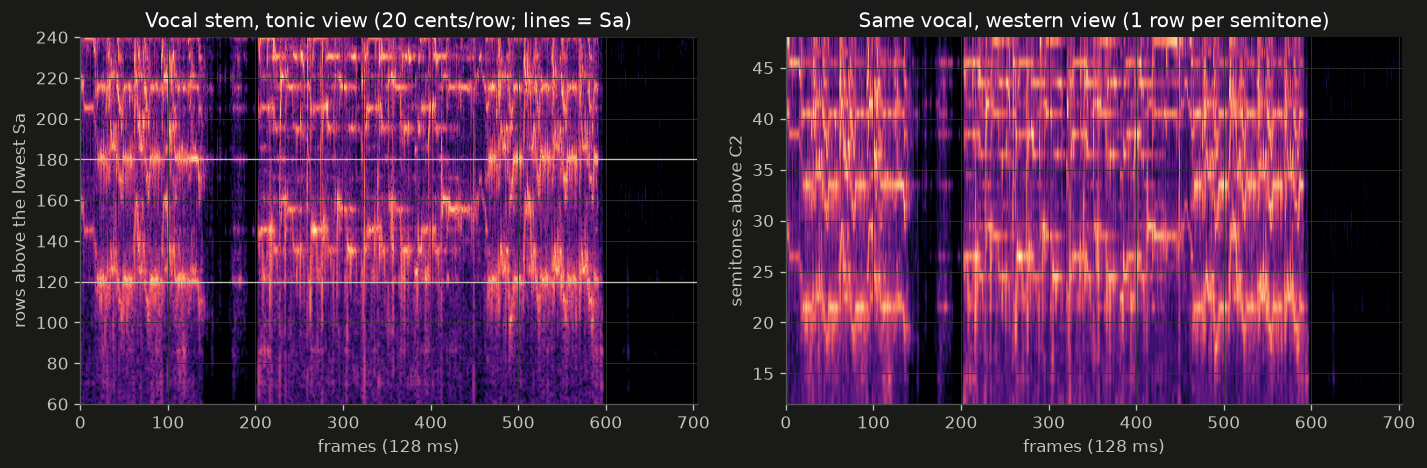

In [19]:
from musicdna.features.cqt import song_cqt, tonic_view, western_view

cqt_signals = {'mix': load_audio(audio_path, vocal_rate)[int(EXCERPT[0] * vocal_rate):int(EXCERPT[1] * vocal_rate)],
               'vocals': vocals, 'drums': drums if len(drums) == len(vocals) else percussive, 'other': other if len(other) == len(vocals) else harmonic}
length = min(len(v) for v in cqt_signals.values())
stored, cqt_meta = song_cqt({k: v[:length] for k, v in cqt_signals.items()}, vocal_rate, tonic.hz, tonic.confidence)
print(f'stored {stored.shape} (channels, rows, frames); tonic offset {cqt_meta.tonic_offset} rows, from {cqt_meta.tonic_source}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
# The singing range: 3 octaves from the second Sa up (rows 60-240 of the tonic view, about 36 semitones).
ax1.imshow(tonic_view(stored, cqt_meta.tonic_offset)[1, 60:240].astype(np.float32), origin='lower', aspect='auto',
           cmap='magma', extent=(0, stored.shape[-1], 60, 240))
ax1.set(title='Vocal stem, tonic view (20 cents/row; lines = Sa)', ylabel='rows above the lowest Sa', xlabel='frames (128 ms)')
for octave in (120, 180):
    ax1.axhline(octave, color=MUTED, linewidth=0.8)
ax2.imshow(western_view(stored)[1, 12:48], origin='lower', aspect='auto', cmap='magma', extent=(0, stored.shape[-1], 12, 48))
ax2.set(title='Same vocal, western view (1 row per semitone)', ylabel='semitones above C2', xlabel='frames (128 ms)')
plt.tight_layout(); plt.show()

## 7. Embeddings (`DeepAudioEncoder`)

General-purpose audio embeddings are the baselines R01/R02 must beat.
- **CLAP** (LAION, Apache-2.0 weights, 512-D). Runs here only if the checkpoint is already in the local
  Hugging Face cache. The notebook never downloads it.
- **MERT** (768-D, CC BY-NC 4.0 weights: non-commercial research only). The pipeline enables it with
  `--allow-nc-weights`; this notebook passes `allow_noncommercial=True` for this research use.
  Its model code comes from Hugging Face (`trust_remote_code=True`); the user approved running it.

Clips come from `FeatureStore.context_clips` with `windows.embedding_context_sec` (default 0 = window only), like `ClapStage`.

W1105 13:50:51.658000 54806 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 447/447 [00:00<00:00, 35011.93it/s]

CLAP: 14 windows x 512-D in 7 s


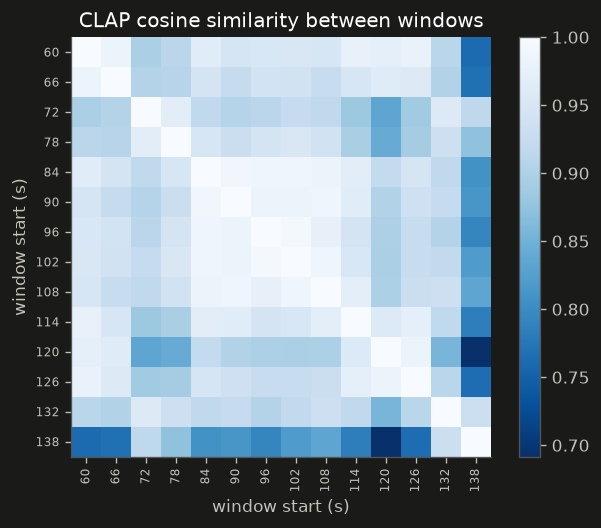

similarity between different windows: min 0.692, median 0.930



Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 30753.66it/s]


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


MERT: 14 windows x 768-D in 10 s


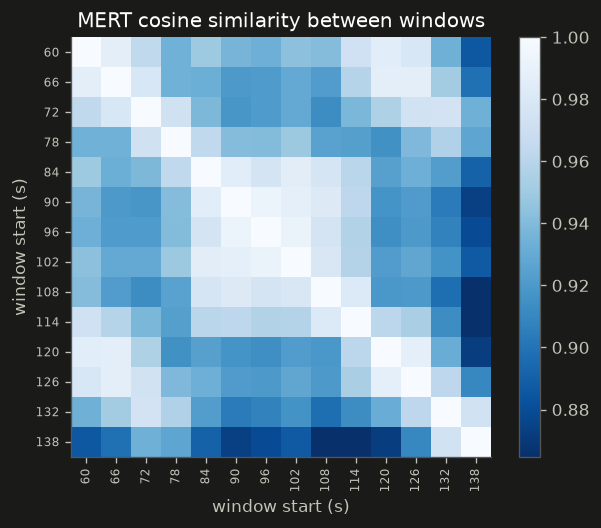

similarity between different windows: min 0.865, median 0.936


In [20]:
if DeepAudioEncoder.hf_clap_is_cached():
    encoder = DeepAudioEncoder()
    context_sec = config.windows.embedding_context_sec
    if song is not None:
        clips = store.context_clips(song, stereo_rate, preroll_sec=context_sec, postroll_sec=context_sec)
        excerpt_clips = [clip for (clip, _), w in zip(clips, windows) if w in excerpt_windows]
    else:
        mono = load_audio(audio_path, stereo_rate)
        excerpt_clips = [mono[int(a * stereo_rate):int(b * stereo_rate)] for a, b in excerpt_windows]
    started = time.time()
    clap = np.array(encoder.encode_clips_with_hf_clap(excerpt_clips, stereo_rate))
    print(f'CLAP: {clap.shape[0]} windows x {clap.shape[1]}-D in {time.time() - started:.0f} s')
    unit = clap / np.linalg.norm(clap, axis=1, keepdims=True)
    similarity = unit @ unit.T
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    image = ax.imshow(similarity, cmap='Blues_r', vmin=similarity.min(), vmax=1)
    labels = [f'{a:g}' for a, _ in excerpt_windows]
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.grid(False)
    ax.set(title='CLAP cosine similarity between windows', xlabel='window start (s)', ylabel='window start (s)')
    fig.colorbar(image, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()
    off_diagonal = similarity[~np.eye(len(similarity), dtype=bool)]
    print(f'similarity between different windows: min {off_diagonal.min():.3f}, median {np.median(off_diagonal):.3f}')
else:
    print('CLAP skipped: the checkpoint is not in the local Hugging Face cache (the notebook does not download it).')
    print('The pipeline downloads it on first run of: python -m musicdna.corpus.feature_store --stages clap')

print()
# MERT: same clips, 768-D, averaged over its 12 layers (CC BY-NC 4.0 weights, research use).
mert_encoder = DeepAudioEncoder()
if 'excerpt_clips' not in dir():
    mono = load_audio(audio_path, stereo_rate)
    excerpt_clips = [mono[int(a * stereo_rate):int(b * stereo_rate)] for a, b in excerpt_windows]
started = time.time()
mert = np.array(mert_encoder.encode_clips_with_mert(excerpt_clips, stereo_rate, allow_noncommercial=True))
print(f'MERT: {mert.shape[0]} windows x {mert.shape[1]}-D in {time.time() - started:.0f} s')
mert_unit = mert / np.linalg.norm(mert, axis=1, keepdims=True)
mert_similarity = mert_unit @ mert_unit.T
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(mert_similarity, cmap='Blues_r', vmin=mert_similarity.min(), vmax=1)
labels = [f'{a:g}' for a, _ in excerpt_windows]
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(labels)), labels, fontsize=7)
ax.grid(False)
ax.set(title='MERT cosine similarity between windows', xlabel='window start (s)', ylabel='window start (s)')
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
mert_off = mert_similarity[~np.eye(len(mert_similarity), dtype=bool)]
print(f'similarity between different windows: min {mert_off.min():.3f}, median {np.median(mert_off):.3f}')


## 8. Listening signals -> preference pairs

The player records what you do while listening. `ListeningEvidenceCollector` turns that into evidence per
window on the same grid:
- **positive**: saved moment, like, loop started, rewound into.
- **negative**: dislike, left early (skip / forward seek away), heard to the end without doing anything.
- never heard = no evidence (silence is not a dislike).

`ImplicitPairBuilder` then pairs each *preferred* window with each non-overlapping *passed-over* window
**of the same song**. **Example:** you rewind to replay 84-96 s, then skip at 160 s -> the 84-96 s window
is preferred over the window you skipped out of.

Set `PROFILE_PATH` to a `music-dna-profile.json` exported from the player to use your real listening.

In [21]:
PROFILE_PATH = None  # e.g. Path.home() / 'Downloads' / 'music-dna-profile.json'

candidates = [Path(PROFILE_PATH)] if PROFILE_PATH else sorted(RESEARCH_OUTPUT_DIR.glob('*profile*.json'))
profile_file = next((p for p in candidates if p.is_file()), None)
if profile_file:
    profile = json.loads(profile_file.read_text(encoding='utf8'))
    profile_is_real = True
    print('Using exported profile:', profile_file)
else:
    profile = None
    profile_is_real = False
    print('No exported profile found; the next cell builds an ILLUSTRATIVE one.')

No exported profile found; the next cell builds an ILLUSTRATIVE one.


### Illustrative profile (made up, not real listening)

Only used when no exported profile was found. It exists to show the mechanics. The pairs it produces are
**not** results.

In [22]:
if profile is None:
    track_title = f'{song.song} - {song.artists}' if song is not None else 'demo'
    track = {'id': 'illustrative-1', 'title': track_title, 'durationSec': round(duration, 1)}
    event = lambda kind, at, origin='user', **fields: {'trackId': track['id'], 'sessionId': 's1', 'kind': kind,
                                                        'origin': origin, 'at': at, **fields}
    profile = {
        'tracks': [track],
        'events': [
            event('listen_span', 1, 'player', fromSec=0, toSec=100),
            event('seek', 2, fromSec=100, toSec=84),              # rewind 16 s: replay 84-100 s
            event('listen_span', 3, 'player', fromSec=84, toSec=165),
            event('skip', 4, positionSec=165),                     # leave early from inside 162-174 s
        ],
        'moments': [{'trackId': track['id'], 'startSec': 84, 'endSec': 96}],   # saved moment
        'ratings': [],
    }
    print('ILLUSTRATIVE profile:', json.dumps({k: len(v) for k, v in profile.items()}))

ILLUSTRATIVE profile: {"tracks": 1, "events": 4, "moments": 1, "ratings": 0}


In [23]:
builder = ImplicitPairBuilder(config)
evidence = builder.label_windows(profile)        # ListeningEvidenceCollector under the hood
assert isinstance(builder.collector, ListeningEvidenceCollector)

evidence_rows = []
for track_id, track_windows in evidence.items():
    for w in track_windows:
        if w.active:
            evidence_rows.append({'track': track_id, 'window': f'{w.start_sec:g}-{w.end_sec:g}', 'heard_s': w.heard_sec,
                                  'positive': ', '.join(w.positive()) or '-',
                                  'negative': ', '.join(w.negative(config.signals)) or '-',
                                  '+score': w.positive_score(config.signals), '-score': w.negative_score(config.signals)})
print(('REAL' if profile_is_real else 'ILLUSTRATIVE') + ' listening evidence (windows with any activity):')
show_table(evidence_rows[:20], digits=1)

pairs = builder.build_pairs(profile, manifest.song_index())
print(f'{len(pairs)} pairs, {sum(p.strength == "strong" for p in pairs)} strong, '
      f'{sum(p.corpus_video_id is not None for p in pairs)} linked to corpus songs')
show_table([{'song': p.track_title[:30], 'corpus_id': p.corpus_video_id, 'preferred': p.preferred,
             'passed_over': p.passed_over, 'why_preferred': ', '.join(p.preferred_evidence),
             'why_passed_over': ', '.join(p.passed_over_evidence), 'weight': p.weight, 'strength': p.strength}
            for p in pairs[:12]], digits=2)

ILLUSTRATIVE listening evidence (windows with any activity):


track,window,heard_s,positive,negative,+score,-score
illustrative-1,0-12,12.0,-,heard_without_action,0.0,1.0
illustrative-1,6-18,12.0,-,heard_without_action,0.0,1.0
illustrative-1,12-24,12.0,-,heard_without_action,0.0,1.0
illustrative-1,18-30,12.0,-,heard_without_action,0.0,1.0
illustrative-1,24-36,12.0,-,heard_without_action,0.0,1.0
illustrative-1,30-42,12.0,-,heard_without_action,0.0,1.0
illustrative-1,36-48,12.0,-,heard_without_action,0.0,1.0
illustrative-1,42-54,12.0,-,heard_without_action,0.0,1.0
illustrative-1,48-60,12.0,-,heard_without_action,0.0,1.0
illustrative-1,54-66,12.0,-,heard_without_action,0.0,1.0


73 pairs, 6 strong, 73 linked to corpus songs


song,corpus_id,preferred,passed_over,why_preferred,why_passed_over,weight,strength
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(0.0, 12.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(6.0, 18.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(12.0, 24.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(18.0, 30.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(24.0, 36.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(30.0, 42.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(36.0, 48.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(42.0, 54.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(48.0, 60.0)","rewound_into, saved_moment",heard_without_action,1.00,weak
Garaj Baras - Rahat Fateh Ali,7rLxN41avhY,"(78.0, 90.0)","(54.0, 66.0)","rewound_into, saved_moment",heard_without_action,1.00,weak


## 9. Experiments: R01 and R02

Both train a **linear pairwise ranker** per feature system and test it on songs (then artists) it never saw.
Main metric: song-averaged pairwise accuracy with a bootstrap 95% CI. Two untrained baselines
(louder window wins, later window wins) catch models that only learned loudness or position.

- **R01**: do vocal pitch features (step 5) add to general embeddings (CLAP/MERT, step 7)?
- **R02**: does microtonal intonation (step 6) add to embeddings, and beyond ornamentation?

They need real listening on corpus songs: at least the minimum below, or the report says `insufficient_data`.

In [24]:
print(f'minimum data: {config.ranker.min_pairs} pairs across {config.ranker.min_songs} songs '
      f'(experiment D: {config.ranker.experiment_d_min_pairs} pairs)')
for name, experiment in (('R01', R01Experiment), ('R02', R02Experiment)):
    print(f'\n{name} systems (feature blocks):')
    for system, blocks in experiment.SYSTEMS.items():
        print(f'  {system:<28} {" + ".join(blocks)}')
    print(f'{name} comparisons: ' + '; '.join(f'{a} vs {b}' for a, b in experiment.COMPARISONS))

minimum data: 20 pairs across 3 songs (experiment D: 500 pairs)

R01 systems (feature blocks):
  dsp                          dsp
  A_clap                       clap
  B_mert                       mert
  C_mert_vocal                 mert + vocal
  C_clap_vocal                 clap + vocal
  C_mert_vocal_spatial         mert + vocal + spatial
  vocal_only                   vocal
  spatial_only                 spatial
R01 comparisons: C_mert_vocal vs B_mert; C_clap_vocal vs A_clap; B_mert vs A_clap; A_clap vs dsp; C_mert_vocal_spatial vs C_mert_vocal; vocal_only vs baseline_louder

R02 systems (feature blocks):
  A_clap                       clap
  B_mert                       mert
  I_intonation                 intonation
  P_pitch_profile              intonation_profile
  O_ornament                   vocal
  A_clap_intonation            clap + intonation
  B_mert_intonation            mert + intonation
  B_mert_ornament              mert + vocal
  B_mert_ornament_intonation   mert + vo

In [25]:
reports = {name: sorted(RESEARCH_OUTPUT_DIR.glob(f'{name}_report*.json')) for name in ('r01', 'r02')}
for name, paths in reports.items():
    if not paths:
        print(f'{name.upper()}: no report in research-output/ yet.')
        continue
    latest = max(paths, key=lambda p: p.stat().st_mtime)
    report = json.loads(latest.read_text())
    print(f'{name.upper()}: {latest.name}  status = {report.get("status")}')
    for system, summary in (report.get('systems') or {}).items():
        print(f'  {system:<28} {summary.get("song_macro_accuracy", summary.get("status"))} {summary.get("ci95", "")}')
    if name == 'r02':
        print('  tonic:', report.get('tonic'))
        print('  singing gate:', report.get('singing_gate'))

if not any(reports.values()):
    print()
    print('To produce them (needs real listening exported from the player):')
    print('  1. import corpus songs into the player and listen normally (save moments, rewind, skip)')
    print('  2. export the profile (music-dna-profile.json)')
    print('  3. python -m musicdna.experiments.pipeline --profile music-dna-profile.json')
    print('     (add --allow-nc-weights for MERT; --set windows.window_sec=10 to change the grid)')
    print('Reports: research-output/r01_report_<hash>.json and r02_report_<hash>.json')

R01: no report in research-output/ yet.
R02: no report in research-output/ yet.

To produce them (needs real listening exported from the player):
  1. import corpus songs into the player and listen normally (save moments, rewind, skip)
  2. export the profile (music-dna-profile.json)
  3. python -m musicdna.experiments.pipeline --profile music-dna-profile.json
     (add --allow-nc-weights for MERT; --set windows.window_sec=10 to change the grid)
Reports: research-output/r01_report_<hash>.json and r02_report_<hash>.json


## Summary of what was measured

In [26]:
print(f'song                : {title}')
print(f'windows             : {len(windows)} x {config.windows.window_sec:g} s (hop {config.windows.hop_sec:g} s, '
      f'roll {config.windows.preroll_sec:g}/{config.windows.postroll_sec:g} s)')
print(f'pitch excerpt       : {EXCERPT[0]:g}-{EXCERPT[1]:g} s')
print(f'singing gate kept   : {gate.kept_fraction:.1%} ({gate.kept_frames}/{gate.tracked_frames} frames; removed {gate.reasons})')
print(f'tonic               : {tonic.hz:.1f} Hz ({librosa.midi_to_note(tonic.midi, cents=True)}), confidence {tonic.confidence:.2f}')
print(f'held notes          : {len(notes)} ({len(slides)} with a slide in), median |ET dev| {np.median(et_abs):.1f} cents')
print(f'preference pairs    : {len(pairs)} ({"real" if profile_is_real else "ILLUSTRATIVE profile, not a result"})')
print(f'notebook run time   : {time.time() - notebook_started:.0f} s')

song                : Garaj Baras | Rahat Fateh Ali Khan & Ali Azmat (S1, classic)
windows             : 78 x 12 s (hop 6 s, roll 1/1 s)
pitch excerpt       : 60-150 s
singing gate kept   : 90.1% (3872/4299 frames; removed {'quiet_vocal': 78, 'low_voicing_probability': 0, 'buried_under_accompaniment': 349})
tonic               : 220.3 Hz (A3+2), confidence 0.13
held notes          : 52 (20 with a slide in), median |ET dev| 3.5 cents
preference pairs    : 73 (ILLUSTRATIVE profile, not a result)
notebook run time   : 206 s
